# Recalibración exploratoria de Zenteno G/F · temperatura

Se repite la calibración química de LAB004–009 del notebook 16 (commit **947f97b**) con dos entradas térmicas. El control usa la temperatura original. La alternativa usa la mediana del último minuto cerrado, conservando el perfil original hasta la primera lectura disponible en LAB004–006. Los dos ajustes usan las mismas muestras tratadas, pesos, parámetros fijos, cotas, semillas y tolerancias del optimizador. Ambos limitan el paso de integración a un minuto para resolver las variaciones térmicas con el mismo criterio numérico.

La referencia vigente usa los parámetros guardados y el perfil original con el integrador del 16. La diferencia **causal frente a control** compara los dos ajustes nuevos. LAB016–018 y LAB022–024 se reservan para evaluar las predicciones con las muestras disponibles. El ensayo se centra en la química de G/F.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json,hashlib,math,time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares,minimize_scalar
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
NAME='16_zenteno_recalibration_legacy_treatment'
data,training,profiles=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))

import os
from types import FunctionType
from unittest.mock import patch
import re
import nbformat

assert Path(os.environ["CONDA_PREFIX"]).resolve() == Path(sys.prefix).resolve()
print(sys.executable)

,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


D:\anaconda3\envs\fermentation\python.exe


## Muestras, pesos y simulador de la calibración original

In [2]:
diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
def simulate(b,p):
 def rhs(t,y):
  out=np.asarray(kin.rhs(t,y,p,b))
  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
  return out
 # Muestra previa al salto si coincide con la nutrición; dosis completa después.
 minimum=np.full(5,np.inf);jumps=[];events={}
 for tp,dose in b.pulses.get('N',()):
  assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
  if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
 times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
 for end in sorted(set([float(times[-1])]+list(events))):
  requested=times[(times>now)&(times<=end)]
  sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
  minimum=np.minimum(minimum,sol.y.min(axis=1))
  records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
  if end in events:
   before=state.copy();state[1]+=events[end]
   assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
   jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
 f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
 f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
 f.attrs['pulse_jumps']=jumps
 assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
 return f

def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
 return pd.concat([f,added]).sort_index(kind='stable')

support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0

Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX aplicada: 0.5


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


In [3]:
def cell(book, marker):
    matches = [c.source for c in book.cells if c.cell_type == "code" and marker in c.source]
    assert len(matches) == 1, marker
    return matches[0]

def run(context, source):
    exec(compile(source, context["__name__"], "exec"), context)

gf = nbformat.read(ROOT / "notebooks/16_zenteno_recalibration_legacy_treatment_variable_solubility.source.ipynb", as_version=4)
context = dict(globals(), __name__="datos_16", display=lambda *args: None)
run(context, cell(gf, "Química congelada").split("traincurves=")[0])
current = context["theta"].copy()
assert all(current[k] == fixed[k] for k in fixed)
reference_temperature = kin.temperature_at
calibration = {b.batch: b for b in treated}
all_batches = calibration
roles = dict.fromkeys(calibration, "Calibración química")

PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}
Química fija: no se recalibra en esta prueba de activación.


In [4]:
def old_sensor(lab):
    clocks = pd.read_csv(ROOT / 'data/compatibility/chemistry/clocks.csv').set_index('batch').t0
    paths = sorted(path for path in (ROOT / 'data/original/natural/process_logs').rglob('*.csv')
                   if path.name.lower().startswith('temp') and
                   re.search(rf'lab0*{int(lab[3:])}(?:\D|$)', path.name, re.I))
    raw = pd.concat([pd.read_csv(path, usecols=['timestamp', 'T']) for path in paths])
    raw['timestamp'] = pd.to_datetime(raw.timestamp, errors='coerce')
    raw['T'] = pd.to_numeric(raw['T'], errors='coerce')
    raw = raw.dropna().sort_values('timestamp', kind='stable').drop_duplicates('timestamp')
    return raw.assign(t_h=(raw.timestamp - pd.Timestamp(clocks[lab])).dt.total_seconds() / 3600)

def measured_temperature(lab):
    if lab in calibration:
        return old_sensor(lab)
    if lab in historical:
        return ctx['v'].raw_temperature[lab]
    raw = ctx['holdout_temperature']
    return raw.loc[raw.lab.eq(lab)].rename(columns={'h': 't_h'})

profiles_1min = {}
coverage = []
for lab, batch in all_batches.items():
    raw = measured_temperature(lab).dropna(subset=['t_h', 'T'])
    minute = np.floor(raw.t_h.to_numpy() * 60 + 1e-10).astype(int)
    median = raw.groupby(minute).T.median()
    available = (median.index.to_numpy() + 1) / 60
    profiles_1min[lab] = (available, median.to_numpy())
    first, end = batch.time[[0, -1]]
    in_range = available[(available > first) & (available <= end)]
    assert len(in_range), lab
    wait = 0. if np.any(available <= first) else in_range[0] - first
    breaks = np.r_[first, in_range, end]
    coverage.append({'LAB': lab, 'Rol': roles[lab], 'Inicio [h]': first,
                     'Hasta [h]': end, 'Prefijo original [min]': 60 * wait,
                     'Mayor intervalo entre actualizaciones [min]': np.diff(breaks).max() * 60})

display(pd.DataFrame(coverage).set_index('LAB').round(2))

def causal_temperature(batch, t):
    available, values = profiles_1min[batch.batch]
    index = np.searchsorted(available, t + 1e-12, side='right') - 1
    return float(values[index]) if index >= 0 else reference_temperature(batch, t)

,Rol,Inicio [h],Hasta [h],Prefijo original [min],Mayor intervalo entre actualizaciones [min]
LAB,,,,,
LAB004,Calibración química,0.0,163.0,107.0,107.0
LAB005,Calibración química,0.0,163.0,107.0,107.0
LAB006,Calibración química,0.0,211.0,108.0,108.0
LAB007,Calibración química,0.0,160.0,0.0,1.0
LAB008,Calibración química,0.0,160.0,0.0,1.0
LAB009,Calibración química,0.0,160.0,0.0,1.0


## Ajustes pareados

In [5]:
def minute_solver(rhs, interval, initial, **kwargs):
    return solve_ivp(rhs, interval, initial, **{**kwargs, "max_step": 1/60})

fit_simulate = FunctionType(simulate.__code__, dict(globals(), solve_ivp=minute_solver))

In [6]:
def fit_chemistry(temperature):
    simulate = fit_simulate
    calls = rejected = 0
    with patch.object(kin, 'temperature_at', temperature):
        def residual(logp):
         nonlocal calls,rejected
         calls+=1;p={**start,**dict(zip(names,np.exp(logp)))}
         try:pred={b.batch:simulate(b,p) for b in treated}
         except (RuntimeError,ValueError,FloatingPointError):
          rejected+=1;return np.full(NR,1e4)
         e=np.concatenate([(pred[b.batch][s].to_numpy()[m]-b.observations[s][m])/sigma(s,b.observations[s][m]) for b,s,m in support])
         if calls%50==0:print('Evaluaciones',calls,'MSE',float(np.mean(e*e)),'rechazos',rejected,flush=True)
         return e
        rng=np.random.default_rng(20261101);x0=np.array([start[k] for k in names]);seeds=[x0,x0*np.exp(rng.normal(0,.2,len(names)))];runs=[];runrows=[]
        for j,seed in enumerate(seeds):
         sol=least_squares(residual,np.log(np.clip(seed,lo+1e-10,hi-1e-10)),bounds=(np.log(lo),np.log(hi)),max_nfev=100,diff_step=1e-3,ftol=2e-5,xtol=2e-5,gtol=2e-5)
         runs.append(sol);runrows.append(dict(inicio=j,success=sol.success,nfev=sol.nfev,MSE=float(np.mean(sol.fun**2)),message=sol.message));print(runrows[-1],flush=True)
        best=min(runs,key=lambda s:s.fun@s.fun);theta={**start,**dict(zip(names,np.exp(best.x)))}
        assert theta['Kd0']==KD0_ZENTENO_H and 'Kd0' not in names
        assert theta['Kn0']==start['Kn0'] and np.isclose(theta['Kn0']*KN_THERMAL_FACTOR,.01,rtol=1e-14)
        assert theta['Yeg']<=.5114 and theta['Yef']<=.5114 and all(theta[k]==v for k,v in fixed.items())

    return theta, runrows, best.fun @ best.fun, calls, rejected

In [7]:
fits = {}
fit_summary = []
for label, temperature in (("Control", reference_temperature), ("Causal", causal_temperature)):
    print(label, flush=True)
    parameters, runs, objective, calls, rejected = fit_chemistry(temperature)
    fits[label] = parameters
    fit_summary.append({"Ajuste": label, "Suma cuadrados ponderada": objective, "Evaluaciones": calls,
                        "Rechazos": rejected, **min(runs, key=lambda row: row["MSE"])})
display(pd.DataFrame(fit_summary).set_index("Ajuste"))
parameters = pd.DataFrame({"Vigente": current, **fits})
parameters["Ajustado"] = parameters.index.isin(names)
parameters["Causal vs control [%]"] = 100 * (parameters["Causal"] / parameters["Control"] - 1)
display(parameters.round(7))
print("PARAMETROS_JSON", json.dumps({"Vigente": current, **fits}))

Control


Evaluaciones 50 MSE 3.2226895348029307 rechazos 0


{'inicio': 0, 'success': True, 'nfev': 11, 'MSE': 3.200749412093197, 'message': '`ftol` termination condition is satisfied.'}


Evaluaciones 100 MSE 29.446552946495775 rechazos 0


Evaluaciones 150 MSE 3.2284038813673637 rechazos 0


Evaluaciones 200 MSE 3.2010387849864976 rechazos 0


... (8 outputs left out)

{'inicio': 1, 'success': True, 'nfev': 18, 'MSE': 3.2213163406769194, 'message': '`ftol` termination condition is satisfied.'}


,Suma cuadrados ponderada,Evaluaciones,Rechazos,inicio,success,nfev,MSE,message
Ajuste,,,,,,,,
Control,905.812084,207,0,0,True,11,3.200749,`ftol` termination condition is satisfied.
Causal,911.167117,266,0,0,True,16,3.219672,`xtol` termination condition is satisfied.


,Vigente,Control,Causal,Ajustado,Causal vs control [%]
mu0,0.094032,0.094049,0.094290,True,0.256231
betaG0,0.422437,0.425394,0.481914,True,13.286565
betaF0,0.623655,0.632300,0.829142,True,31.131182
Kn0,0.008258,0.008258,0.008258,False,0.000000
Kg0,4.400775,4.400775,4.400775,False,0.000000
Kf0,19.296084,19.296084,19.296084,False,0.000000
Kig0,65.019939,63.718176,45.938232,True,-27.904037
Kie0,96.265166,93.878148,60.679862,True,-35.363167
Kd0,0.000440,0.000440,0.000440,False,0.000000
Yxn,6.456226,6.459425,6.563249,True,1.607333


PARAMETROS_JSON {"Vigente": {"mu0": 0.09403147367985473, "betaG0": 0.42243676903335664, "betaF0": 0.6236552480900203, "Kn0": 0.008257860224319971, "Kg0": 4.400775419123265, "Kf0": 19.296083508118652, "Kig0": 65.01993873457147, "Kie0": 96.26516563486751, "Kd0": 0.00044, "Yxn": 6.456225797038313, "Yxg": 0.9660935553477866, "Yxf": 1.1098958529485594, "Yeg": 0.4684585383875136, "Yef": 0.5113278649826252, "m0": 0.0183385793928771}, "Control": {"mu0": 0.09404885409255383, "betaG0": 0.4253939125603839, "betaF0": 0.6322995148096726, "Kn0": 0.008257860224319971, "Kg0": 4.400775419123265, "Kf0": 19.296083508118652, "Kig0": 63.71817600961053, "Kie0": 93.87814835086799, "Kd0": 0.00044, "Yxn": 6.459424662297984, "Yxg": 0.9660935553477866, "Yxf": 1.1098958529485594, "Yeg": 0.4687460855466198, "Yef": 0.5109654789897142, "m0": 0.0183385793928771}, "Causal": {"mu0": 0.09428983609051796, "betaG0": 0.4819141520103712, "betaF0": 0.8291418256832069, "Kn0": 0.008257860224319971, "Kg0": 4.400775419123265, "K

## Evaluación por lote

In [8]:
gas_cell = cell(gf, 'def calibrate_gas')
batch_setup = gas_cell.split('PCO2_BAR=')[0]
first = batch_setup.index(' batches[lab]=b;f=simulate')
last = batch_setup.index(' obs[lab]=obs[lab].loc', first)
run(context, batch_setup[:first] + ' batches[lab]=b\n' + batch_setup[last:])
run(context, cell(gf, 'def read_holdout_backup'))
run(context, cell(gf, 'def simulate_holdout').split('\nholdout_kinetic,')[0])
historical = context['batches']
recent = context['holdout_batches']
all_batches = {**calibration, **historical, **recent}
roles.update({lab: ('Evaluación química' if lab in context['TRAIN'] else 'Holdout')
              for lab in (*historical, *recent)})
ctx = context

In [9]:
def measured_temperature(lab):
    if lab in calibration:
        return old_sensor(lab)
    if lab in historical:
        return ctx['v'].raw_temperature[lab]
    raw = ctx['holdout_temperature']
    return raw.loc[raw.lab.eq(lab)].rename(columns={'h': 't_h'})

profiles_1min = {}
coverage = []
for lab, batch in all_batches.items():
    raw = measured_temperature(lab).dropna(subset=['t_h', 'T'])
    minute = np.floor(raw.t_h.to_numpy() * 60 + 1e-10).astype(int)
    median = raw.groupby(minute).T.median()
    available = (median.index.to_numpy() + 1) / 60
    profiles_1min[lab] = (available, median.to_numpy())
    first, end = batch.time[[0, -1]]
    in_range = available[(available > first) & (available <= end)]
    assert len(in_range), lab
    wait = 0. if np.any(available <= first) else in_range[0] - first
    breaks = np.r_[first, in_range, end]
    coverage.append({'LAB': lab, 'Rol': roles[lab], 'Inicio [h]': first,
                     'Hasta [h]': end, 'Prefijo original [min]': 60 * wait,
                     'Mayor intervalo entre actualizaciones [min]': np.diff(breaks).max() * 60})

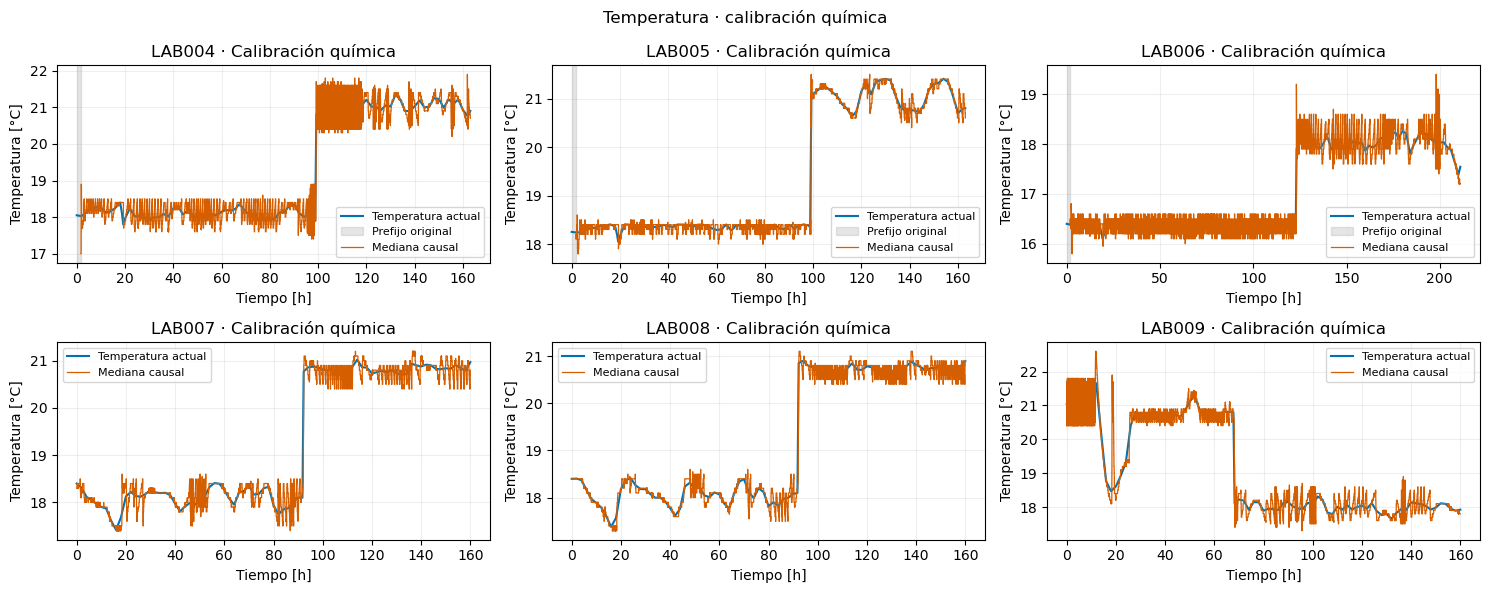

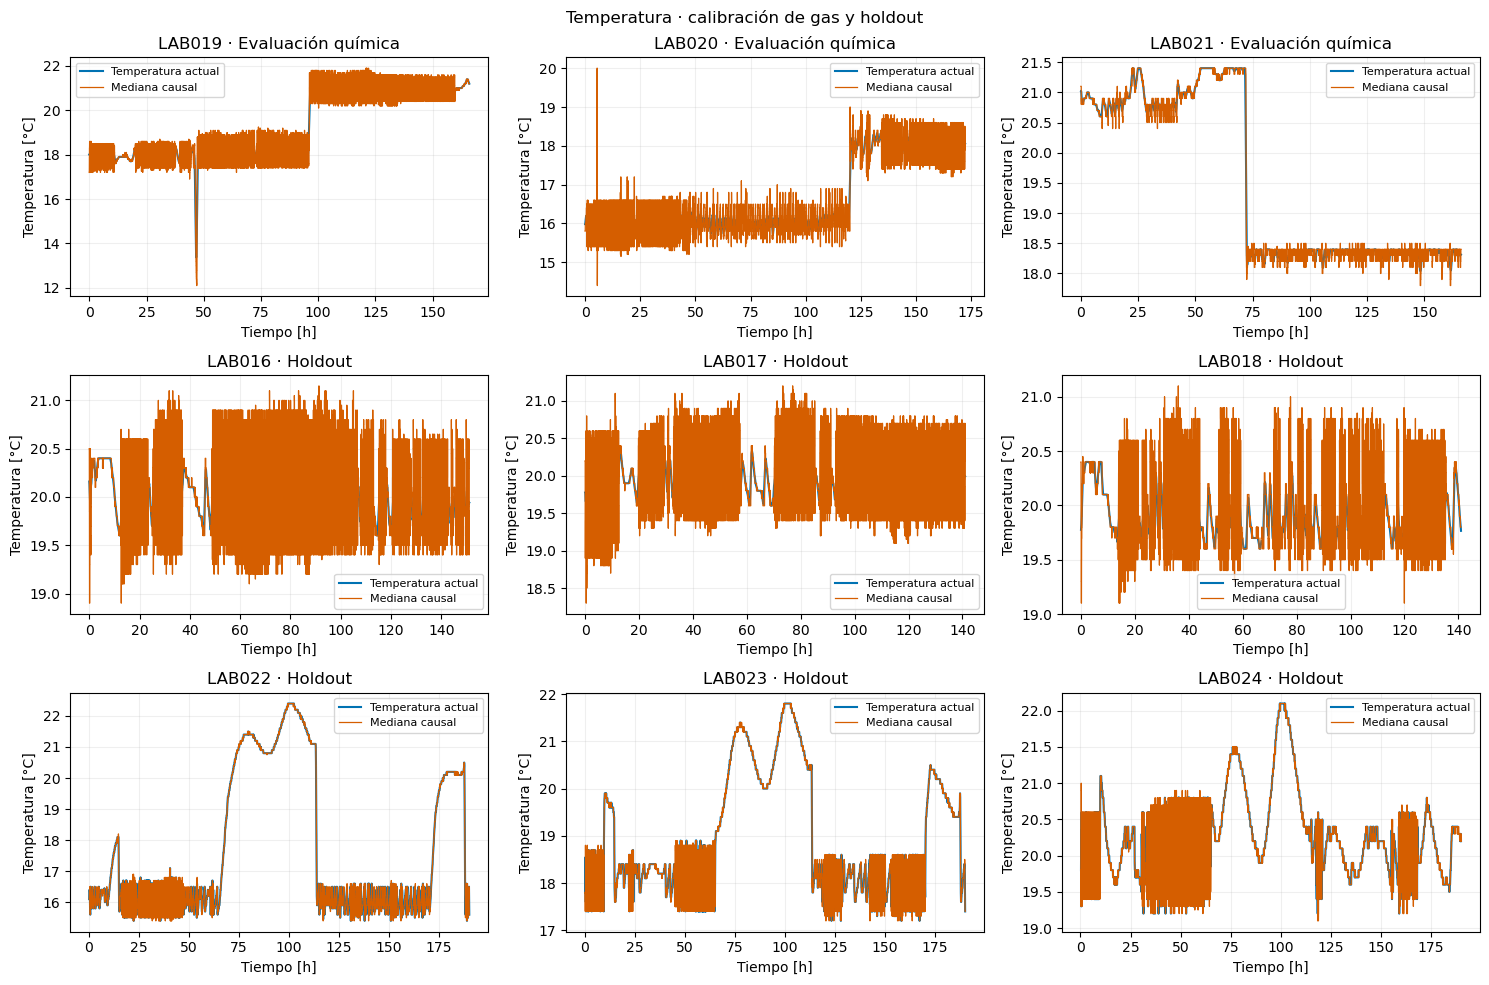

In [10]:
def temperature_figure(labs, title):
    fig, axes = plt.subplots(len(labs) // 3, 3, figsize=(15, 3.4 * len(labs) // 3))
    for ax, lab in zip(axes.flat, labs):
        batch = all_batches[lab]
        available, values = profiles_1min[lab]
        start = batch.time[0]
        end = ctx['v'].horizons[lab] if lab in historical else batch.time[-1]
        wait = next(row['Prefijo original [min]'] for row in coverage if row['LAB'] == lab)
        original_times = np.r_[batch.time[batch.time < end], end]
        ax.plot(original_times, np.interp(original_times, batch.time, batch.temperature_c),
                color='#0072B2', label='Temperatura actual', lw=1.5)
        mask = (available > start) & (available < end)
        times = np.r_[start, available[mask], end]
        temperatures = np.r_[causal_temperature(batch, start), values[mask], causal_temperature(batch, end)]
        if wait > 0:
            ax.axvspan(start, start + wait/60, color='gray', alpha=.2, label='Prefijo original')
            times, temperatures = times[1:], temperatures[1:]
        ax.step(times, temperatures, where='post', color='#D55E00', lw=.9, label='Mediana causal')
        ax.set(title=f'{lab} · {roles[lab]}', xlabel='Tiempo [h]', ylabel='Temperatura [°C]')
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

temperature_figure(list(calibration), 'Temperatura · calibración química')
temperature_figure([*historical, *recent], 'Temperatura · calibración de gas y holdout')

In [11]:
def predict_chemistry(parameters, temperature, solver):
    holdout_context = dict(context, theta=parameters, solve_ivp=solver)
    integrate = FunctionType(context['simulate_holdout'].__code__, holdout_context)
    run_kinetics = FunctionType(simulate.__code__, dict(globals(), solve_ivp=solver))
    with patch.object(kin, 'temperature_at', temperature):
        return {lab: integrate(batch) if lab in recent else run_kinetics(batch, parameters)
                for lab, batch in all_batches.items()}

trajectories = {
    "Vigente": predict_chemistry(current, reference_temperature, solve_ivp),
    "Control": predict_chemistry(fits["Control"], reference_temperature, minute_solver),
    "Causal": predict_chemistry(fits["Causal"], causal_temperature, minute_solver),
}
curves = {label: {lab: with_jumps(f) for lab, f in values.items()} for label, values in trajectories.items()}

In [12]:
labels = {
    'X': ('Biomasa', 'g/L'), 'N': ('YAN', 'mg N/L'),
    'G': ('Glucosa', 'g/L'), 'F': ('Fructosa', 'g/L'), 'GF': ('Azúcar total', 'g/L'),
    'E': ('Etanol', 'g/L'), 'CO2': ('Flujo de CO₂', 'g/(L h)'),
}
recent_columns = {'X': 'X_g_L', 'N': 'YAN for plot', 'G': 'GLUCOSE-320',
                  'F': 'Fructose (derived)', 'GF': 'GLU-FRU-320'}

def samples(lab, variable):
    if lab in calibration:
        b = calibration[lab]
        y = b.observations[variable] if variable != 'GF' else b.observations['G'] + b.observations['F']
        return b.time, y * (1000 if variable == 'N' else 1), 'Muestras tratadas'
    if lab in recent:
        if variable not in recent_columns:
            return np.array([]), np.array([]), ''
        table = ctx['holdout_biomass'] if variable == 'X' else ctx['holdout_chemistry']
        z = table.loc[table.lab.eq(lab)].dropna(subset=[recent_columns[variable]])
        return z.hours.to_numpy(), z[recent_columns[variable]].to_numpy(), 'Muestras'
    v = ctx['v']
    if lab in ctx['TRAIN']:
        z = ctx['chemical_observations'](v.chem, lab, variable)
        return z.t_h.to_numpy(), z[ctx['CHEMICAL_COLUMNS'][variable]].to_numpy() * (1000 if variable == 'N' else 1), 'Muestras'
    if variable == 'X':
        z = v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h', 'X_viable_g_l'])
        return z.t_h.to_numpy(), z.X_viable_g_l.to_numpy(), 'Muestras'
    if variable == 'GF':
        z = v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h', 'density_g_l'])
        return z.t_h.to_numpy(), 2.5 * (z.density_g_l.to_numpy() - 1000), 'Azúcar por densidad'
    return np.array([]), np.array([]), ''

In [13]:
def evaluation(lab, state):
    batch = all_batches[lab]
    end = ctx["v"].horizons[lab] if lab in historical else batch.time[-1]
    t, y, origin = samples(lab, state)
    keep = np.isfinite(y) & (t > batch.time[0] + 1e-9) & (t <= end)
    scale = 1000 if state == "N" else 1
    row = {"LAB": lab, "Grupo": roles[lab], "Variable": labels[state][0], "Unidad": labels[state][1],
           "n": int(keep.sum()), "Referencia": origin}
    for label, results in trajectories.items():
        f = curves[label][lab] if lab in historical else results[lab]
        row[label] = (np.sqrt(np.mean((np.interp(t[keep], f.index, f[state]) * scale - y[keep])**2))
                      if keep.any() else np.nan)
    row["Causal − control"] = row["Causal"] - row["Control"]
    return row

states_to_show = ["X", "N", "G", "F", "GF", "E"]
metrics = {(lab, state): evaluation(lab, state) for lab in all_batches for state in states_to_show}
for group in (["X", "N"], ["G", "F", "GF", "E"]):
    display(pd.DataFrame([row for (_, state), row in metrics.items() if state in group]).round(5))
print("RMSE_JSON", pd.DataFrame(metrics.values()).to_json(orient="records"))

,LAB,Grupo,Variable,Unidad,n,Referencia,Vigente,Control,Causal,Causal − control
0,LAB004,Calibración química,Biomasa,g/L,10,Muestras tratadas,0.35379,0.35439,0.37403,0.01964
1,LAB004,Calibración química,YAN,mg N/L,8,Muestras tratadas,26.63859,26.63468,26.41544,-0.21924
2,LAB005,Calibración química,Biomasa,g/L,10,Muestras tratadas,0.24555,0.24620,0.26682,0.02062
3,LAB005,Calibración química,YAN,mg N/L,8,Muestras tratadas,29.09195,29.08590,28.65468,-0.43122
4,LAB006,Calibración química,Biomasa,g/L,12,Muestras tratadas,0.47118,0.47115,0.47189,0.00073
5,LAB006,Calibración química,YAN,mg N/L,9,Muestras tratadas,27.90660,27.90967,28.13793,0.22825
6,LAB007,Calibración química,Biomasa,g/L,11,Muestras tratadas,0.43061,0.43144,0.45724,0.02579
7,LAB007,Calibración química,YAN,mg N/L,8,Muestras tratadas,27.33672,27.33363,26.98931,-0.34431
8,LAB008,Calibración química,Biomasa,g/L,11,Muestras tratadas,0.39748,0.39819,0.42176,0.02356
9,LAB008,Calibración química,YAN,mg N/L,8,Muestras tratadas,21.48920,21.48943,21.35666,-0.13277


,LAB,Grupo,Variable,Unidad,n,Referencia,Vigente,Control,Causal,Causal − control
0,LAB004,Calibración química,Glucosa,g/L,12,Muestras tratadas,3.30370,3.31536,3.51111,0.19575
1,LAB004,Calibración química,Fructosa,g/L,12,Muestras tratadas,6.86155,6.86282,6.90480,0.04198
2,LAB004,Calibración química,Azúcar total,g/L,12,Muestras tratadas,10.05511,10.06860,10.29167,0.22307
3,LAB004,Calibración química,Etanol,g/L,4,Muestras tratadas,4.87954,4.88233,4.87648,-0.00585
4,LAB005,Calibración química,Glucosa,g/L,12,Muestras tratadas,2.07445,2.07106,1.98290,-0.08816
5,LAB005,Calibración química,Fructosa,g/L,12,Muestras tratadas,6.22639,6.22291,6.21293,-0.00998
6,LAB005,Calibración química,Azúcar total,g/L,12,Muestras tratadas,5.50095,5.47872,5.16714,-0.31158
7,LAB005,Calibración química,Etanol,g/L,4,Muestras tratadas,5.43124,5.42850,5.37608,-0.05242
8,LAB006,Calibración química,Glucosa,g/L,14,Muestras tratadas,9.36371,9.35095,9.16482,-0.18612
9,LAB006,Calibración química,Fructosa,g/L,14,Muestras tratadas,4.27310,4.29601,4.66980,0.37379


RMSE_JSON [{"LAB":"LAB004","Grupo":"Calibraci\u00f3n qu\u00edmica","Variable":"Biomasa","Unidad":"g\/L","n":10,"Referencia":"Muestras tratadas","Vigente":0.3537888032,"Control":0.354391136,"Causal":0.3740342761,"Causal \u2212 control":0.01964314},{"LAB":"LAB004","Grupo":"Calibraci\u00f3n qu\u00edmica","Variable":"YAN","Unidad":"mg N\/L","n":8,"Referencia":"Muestras tratadas","Vigente":26.6385930409,"Control":26.634680494,"Causal":26.4154438253,"Causal \u2212 control":-0.2192366687},{"LAB":"LAB004","Grupo":"Calibraci\u00f3n qu\u00edmica","Variable":"Glucosa","Unidad":"g\/L","n":12,"Referencia":"Muestras tratadas","Vigente":3.3037014,"Control":3.3153596159,"Causal":3.5111089973,"Causal \u2212 control":0.1957493814},{"LAB":"LAB004","Grupo":"Calibraci\u00f3n qu\u00edmica","Variable":"Fructosa","Unidad":"g\/L","n":12,"Referencia":"Muestras tratadas","Vigente":6.8615486158,"Control":6.8628158966,"Causal":6.9047994384,"Causal \u2212 control":0.0419835418},{"LAB":"LAB004","Grupo":"Calibraci\u0

In [14]:
def plot_comparison(state, labs, title):
    rows = len(labs) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(15, 3.5 * rows))
    name, unit = labels[state]
    scale = 1000 if state == "N" else 1
    for ax, lab in zip(axes.flat, labs):
        batch = all_batches[lab]
        end = ctx["v"].horizons[lab] if lab in historical else batch.time[-1]
        for label, color, style in (("Vigente", "gray", ":"), ("Control", "#0072B2", "-"),
                                    ("Causal", "#D55E00", "--")):
            f = curves[label][lab]
            ax.plot(f.index, f[state] * scale, color=color, ls=style, lw=1.4, label=label)
        t, y, origin = samples(lab, state)
        visible = np.isfinite(y) & (t <= end)
        if visible.any():
            marker = "D" if origin == "Azúcar por densidad" else "o"
            ax.scatter(t[visible], y[visible], marker=marker, c="black", s=18, zorder=5, label=origin)
        if state == "N":
            for i, (hour, _) in enumerate(batch.pulses["N"]):
                ax.axvline(hour, color="gray", ls=":", lw=.8, label="Pulso N" if i == 0 else None)
        r = metrics[lab, state]
        rmse = ("RMSE vigente / control / causal\n" + " / ".join(f"{r[k]:.3f}" for k in trajectories)
                if r["n"] else "Sin muestras para RMSE")
        ax.set(title=f"{lab} · {roles[lab]}", xlabel="Tiempo [h]", ylabel=f"{name} [{unit}]",
               xlim=(batch.time[0] - 2, end + 2))
        ax.grid(alpha=.2)
        ax.legend(title=rmse, fontsize=7, title_fontsize=7)
    fig.suptitle(f"{name} · {title}")
    fig.tight_layout()
    plt.show()

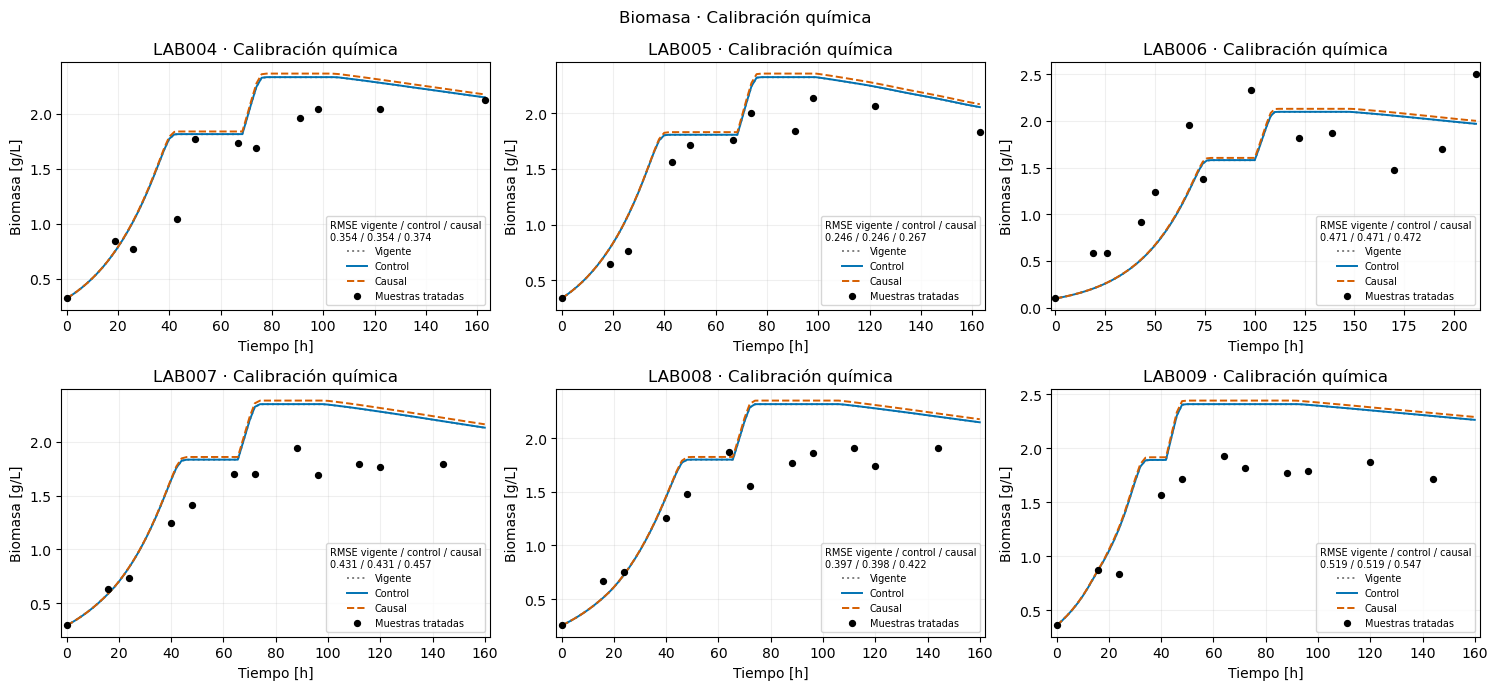

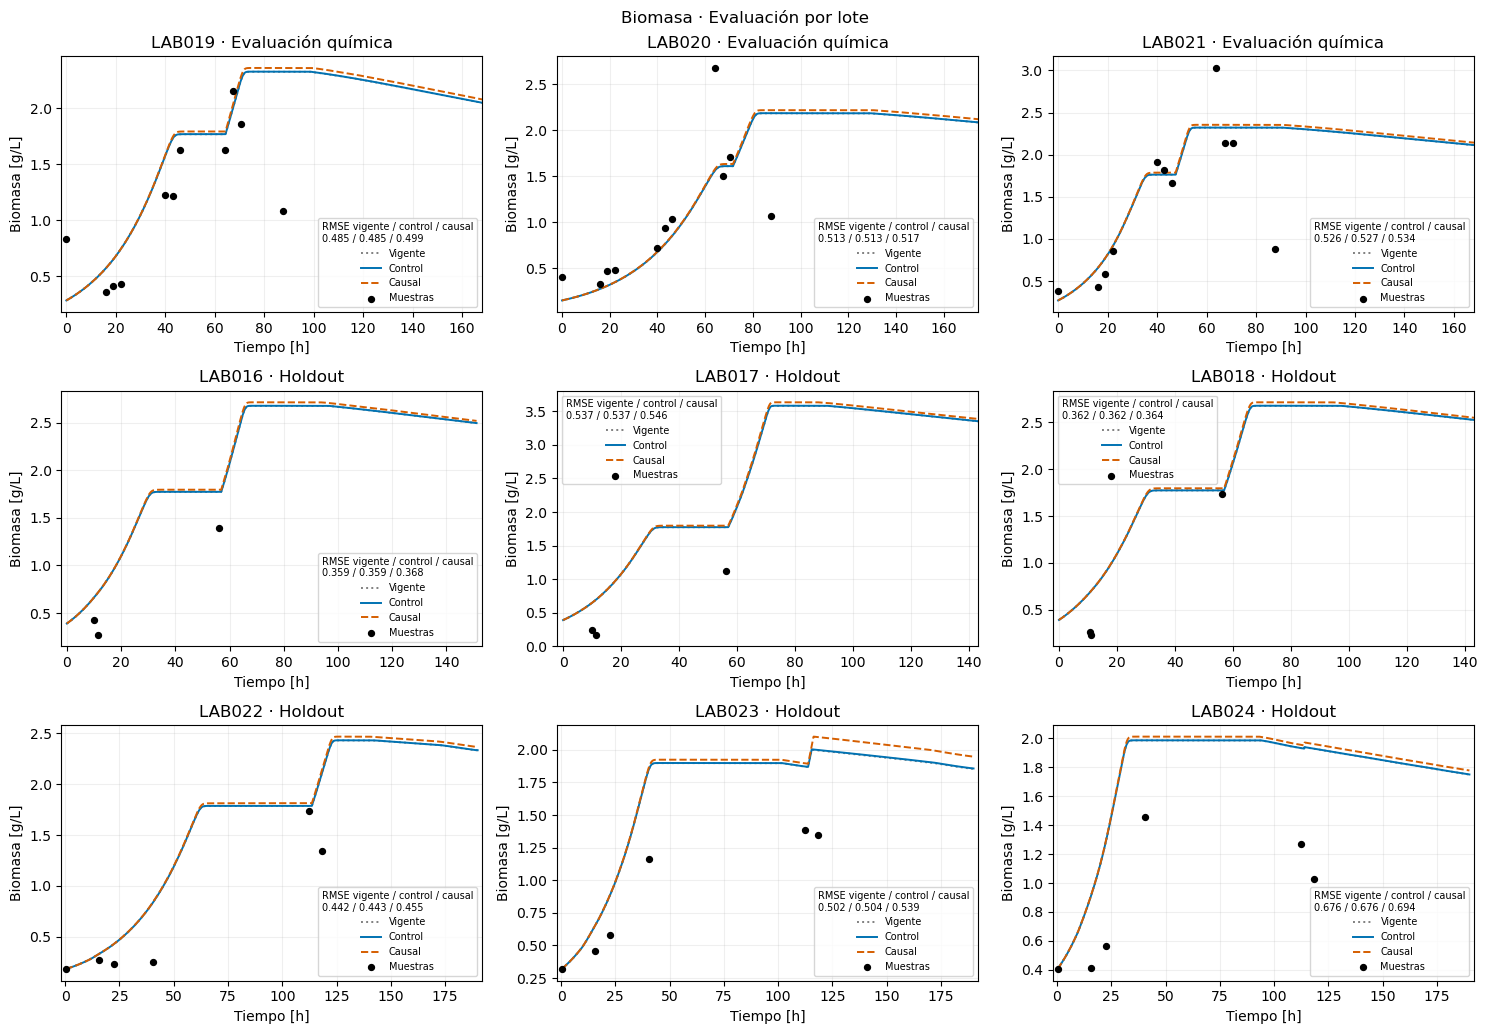

In [15]:
plot_comparison('X', list(calibration), 'Calibración química')
plot_comparison('X', [*historical, *recent], 'Evaluación por lote')

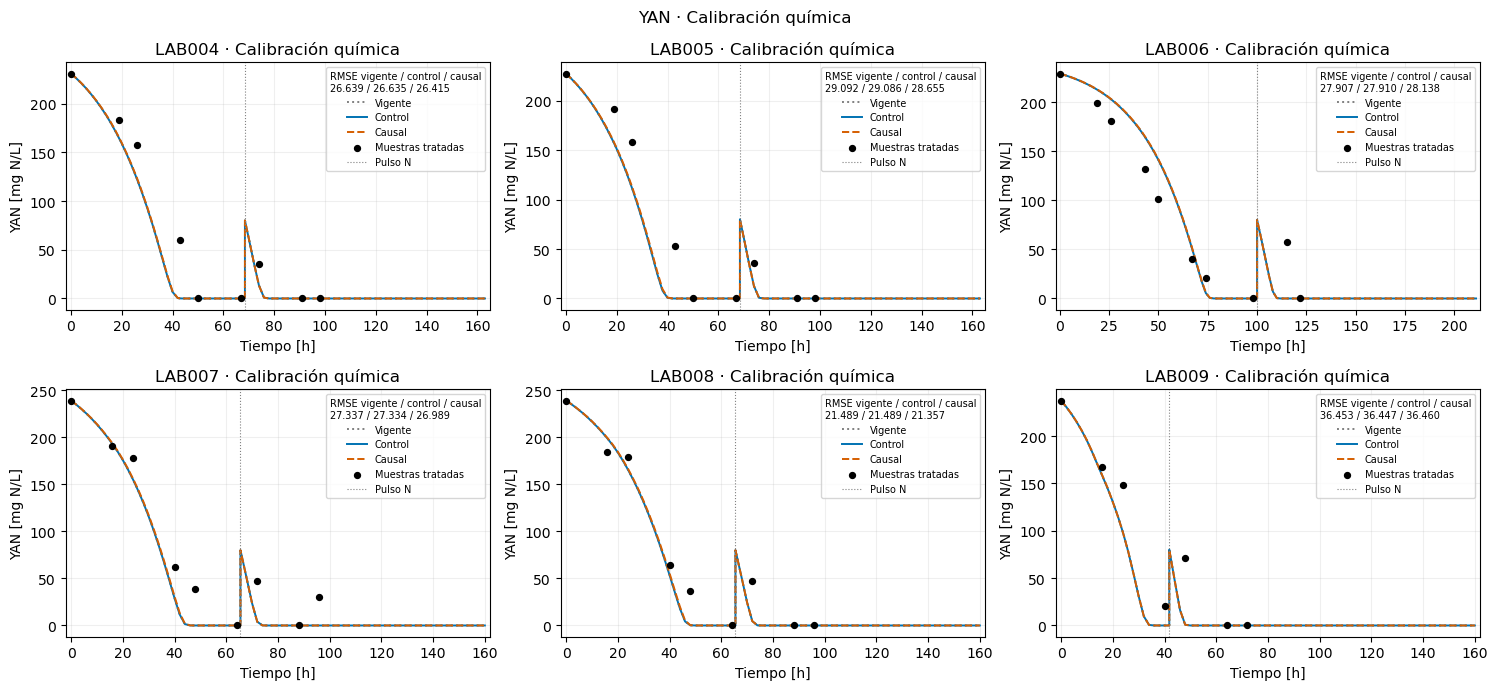

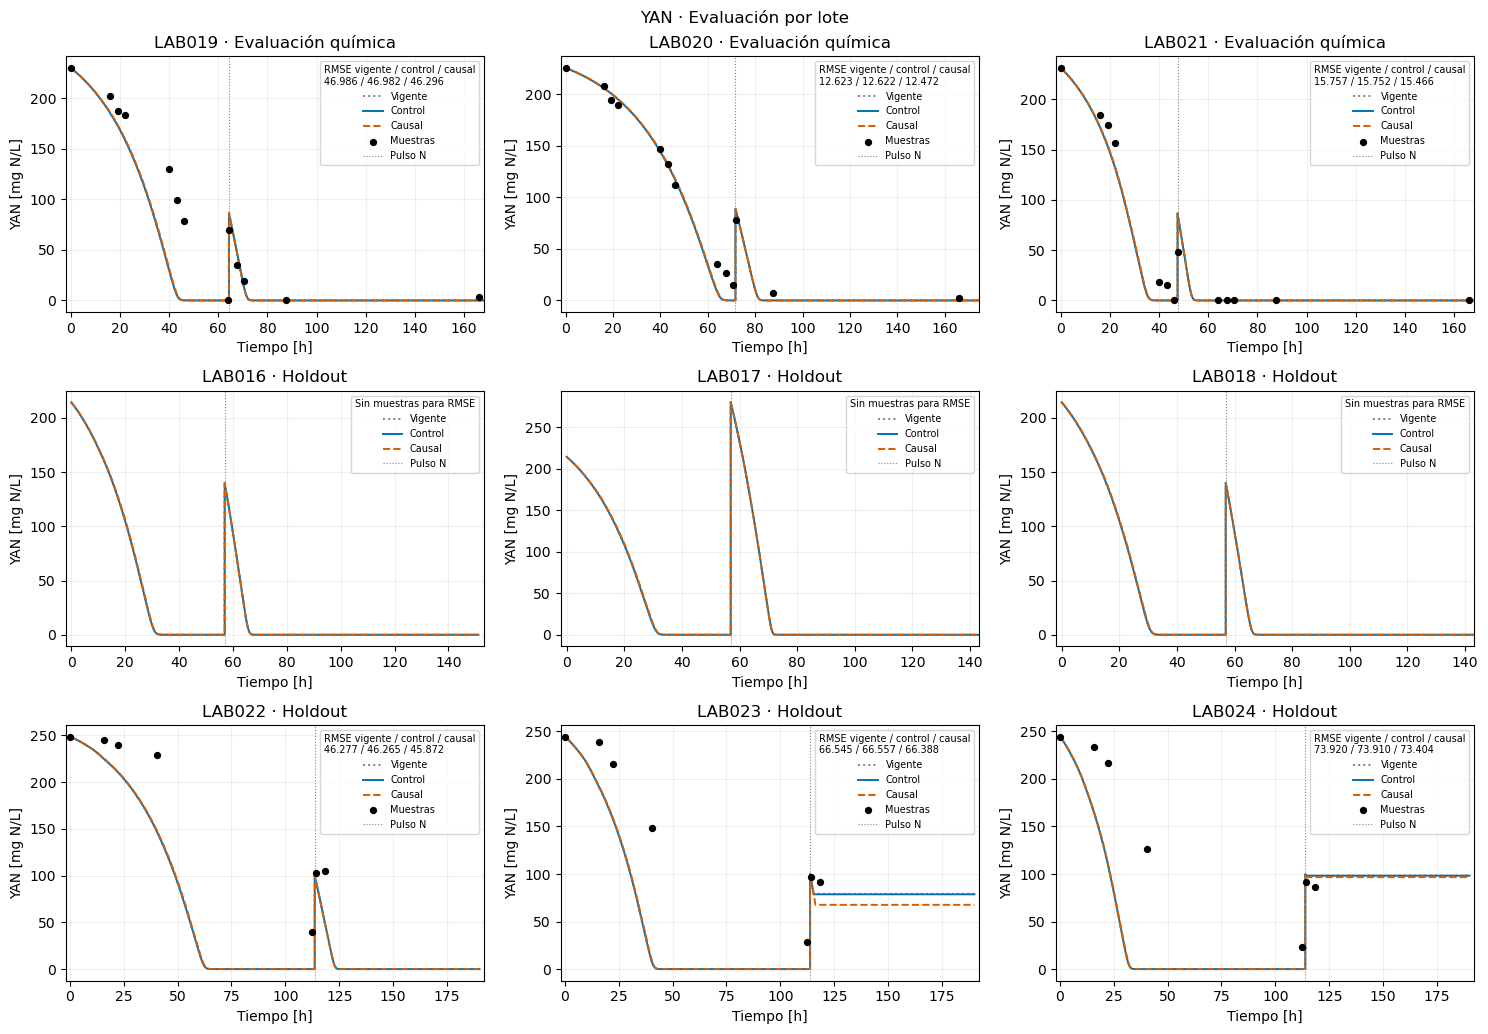

In [16]:
plot_comparison('N', list(calibration), 'Calibración química')
plot_comparison('N', [*historical, *recent], 'Evaluación por lote')

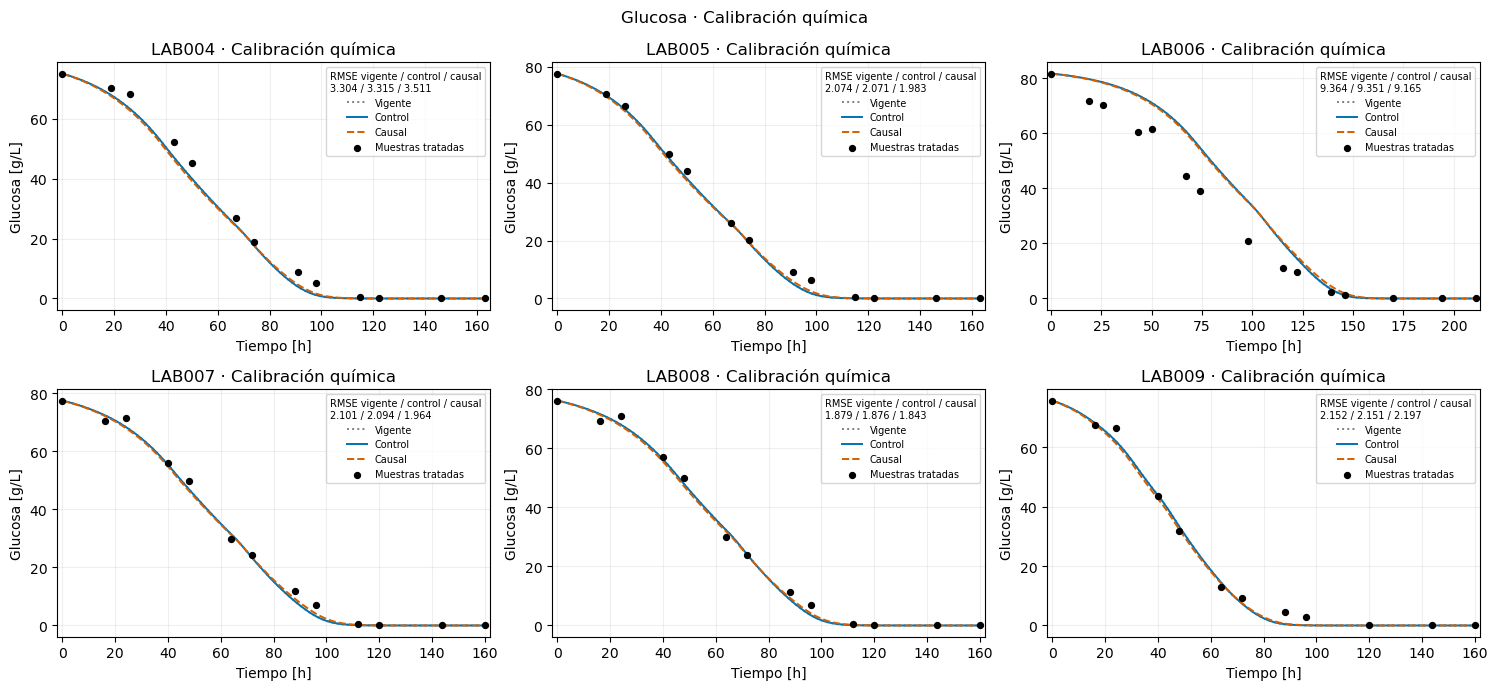

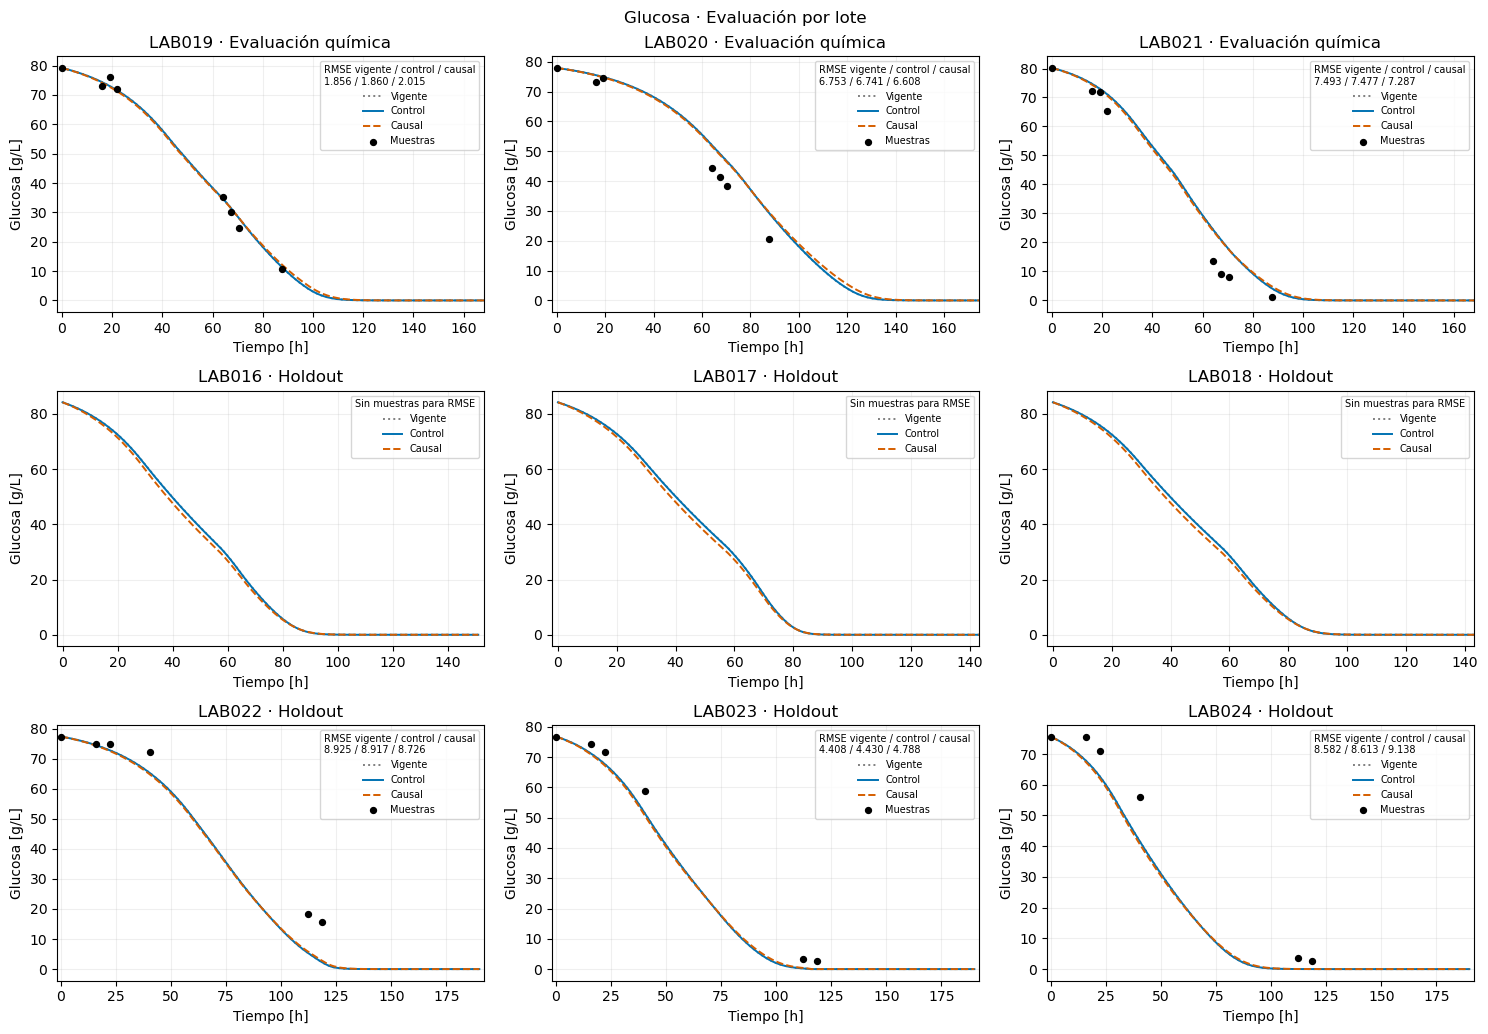

In [17]:
plot_comparison('G', list(calibration), 'Calibración química')
plot_comparison('G', [*historical, *recent], 'Evaluación por lote')

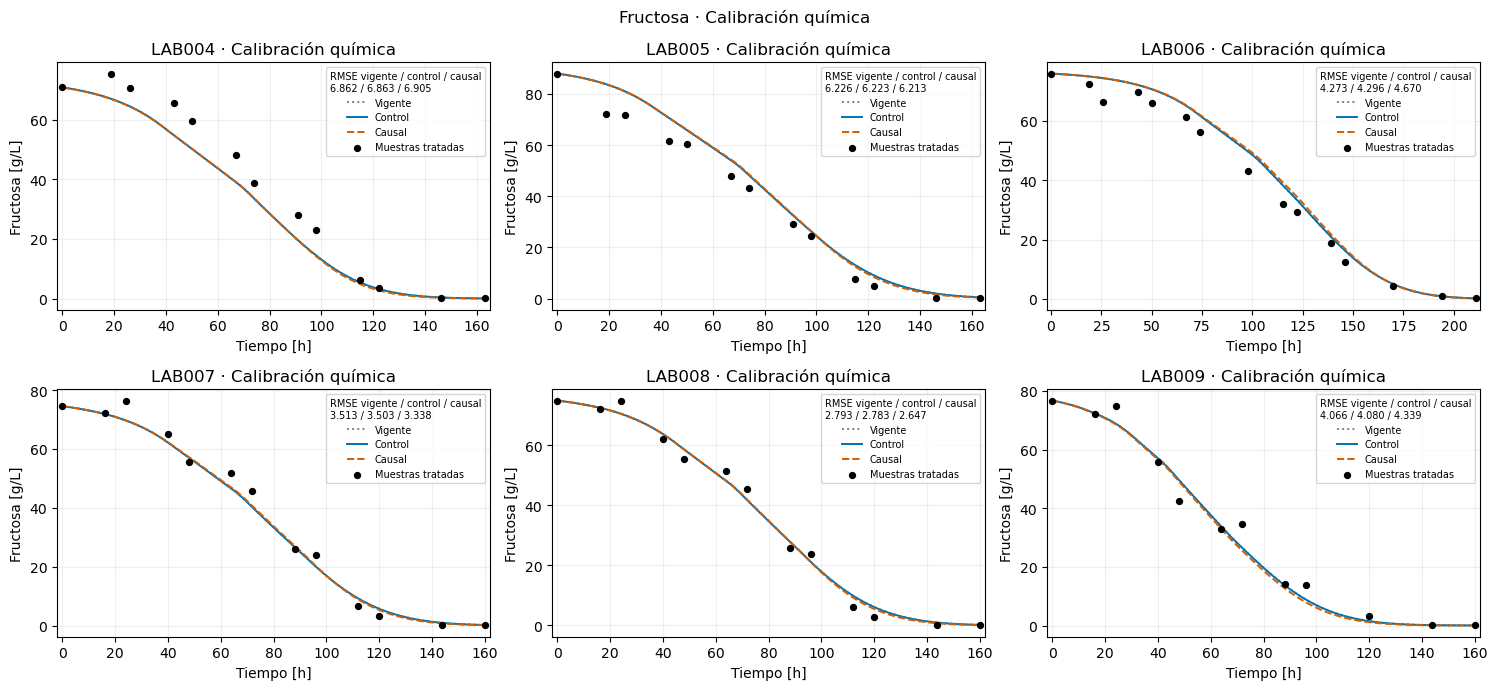

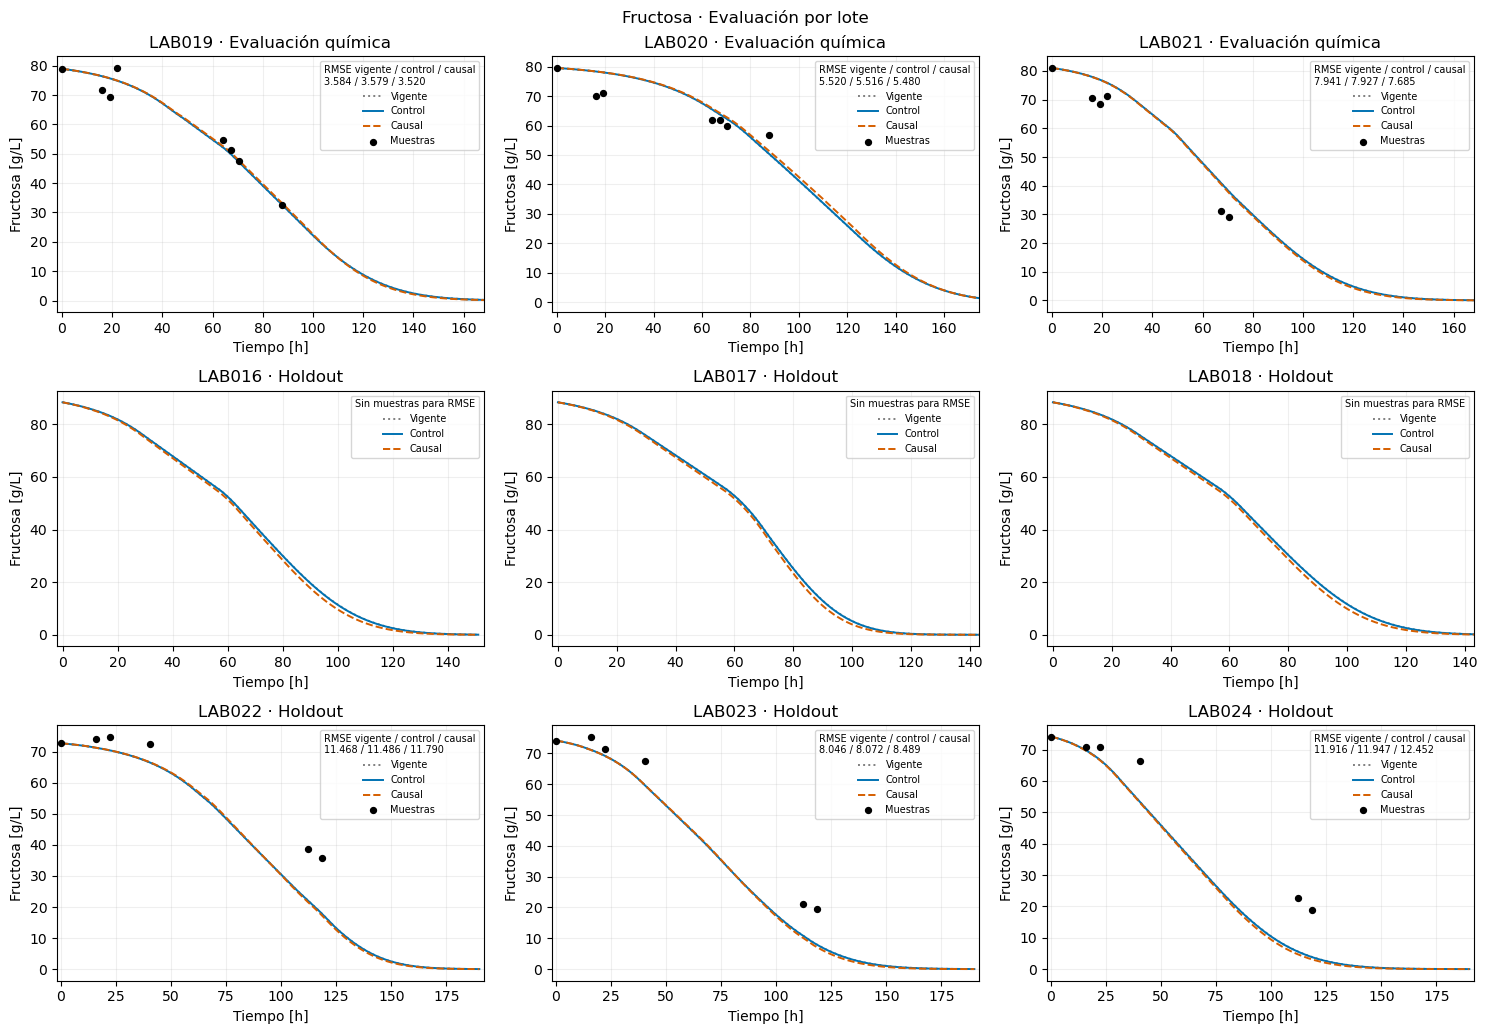

In [18]:
plot_comparison('F', list(calibration), 'Calibración química')
plot_comparison('F', [*historical, *recent], 'Evaluación por lote')

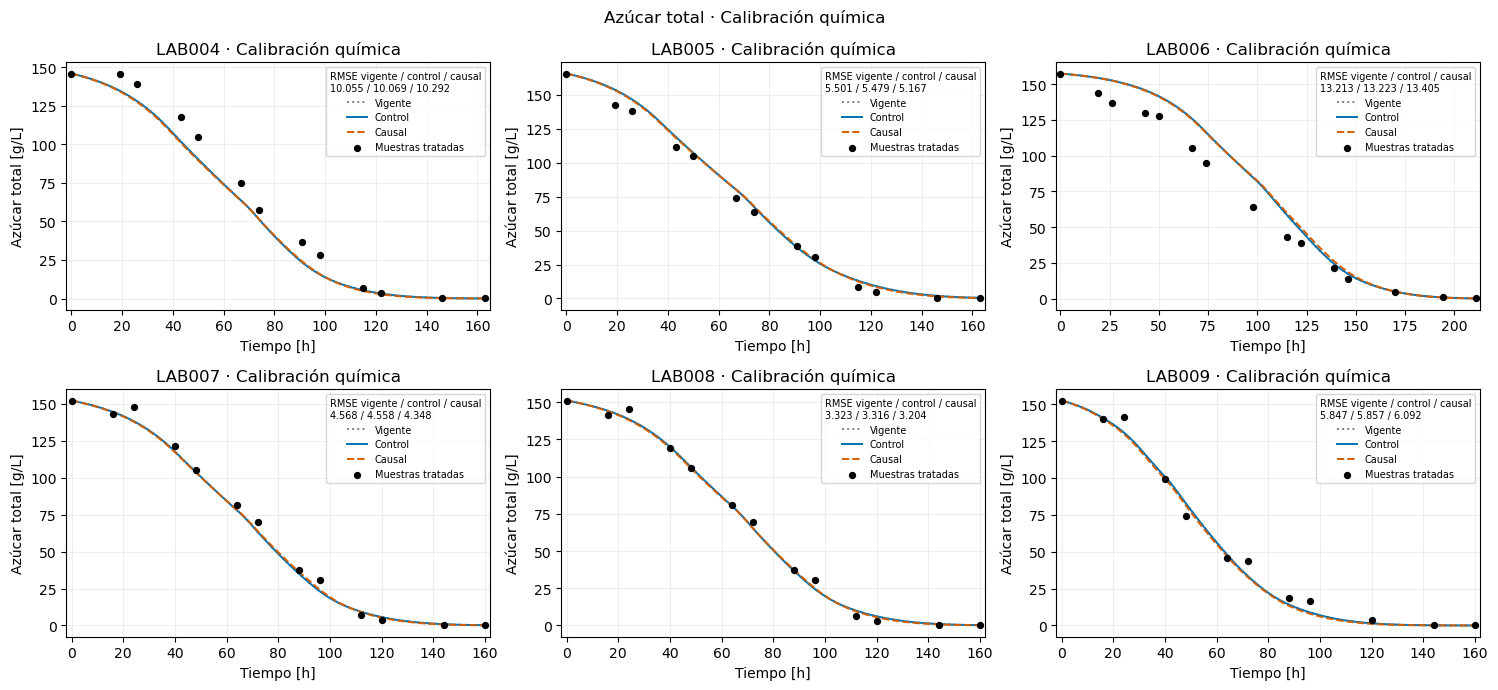

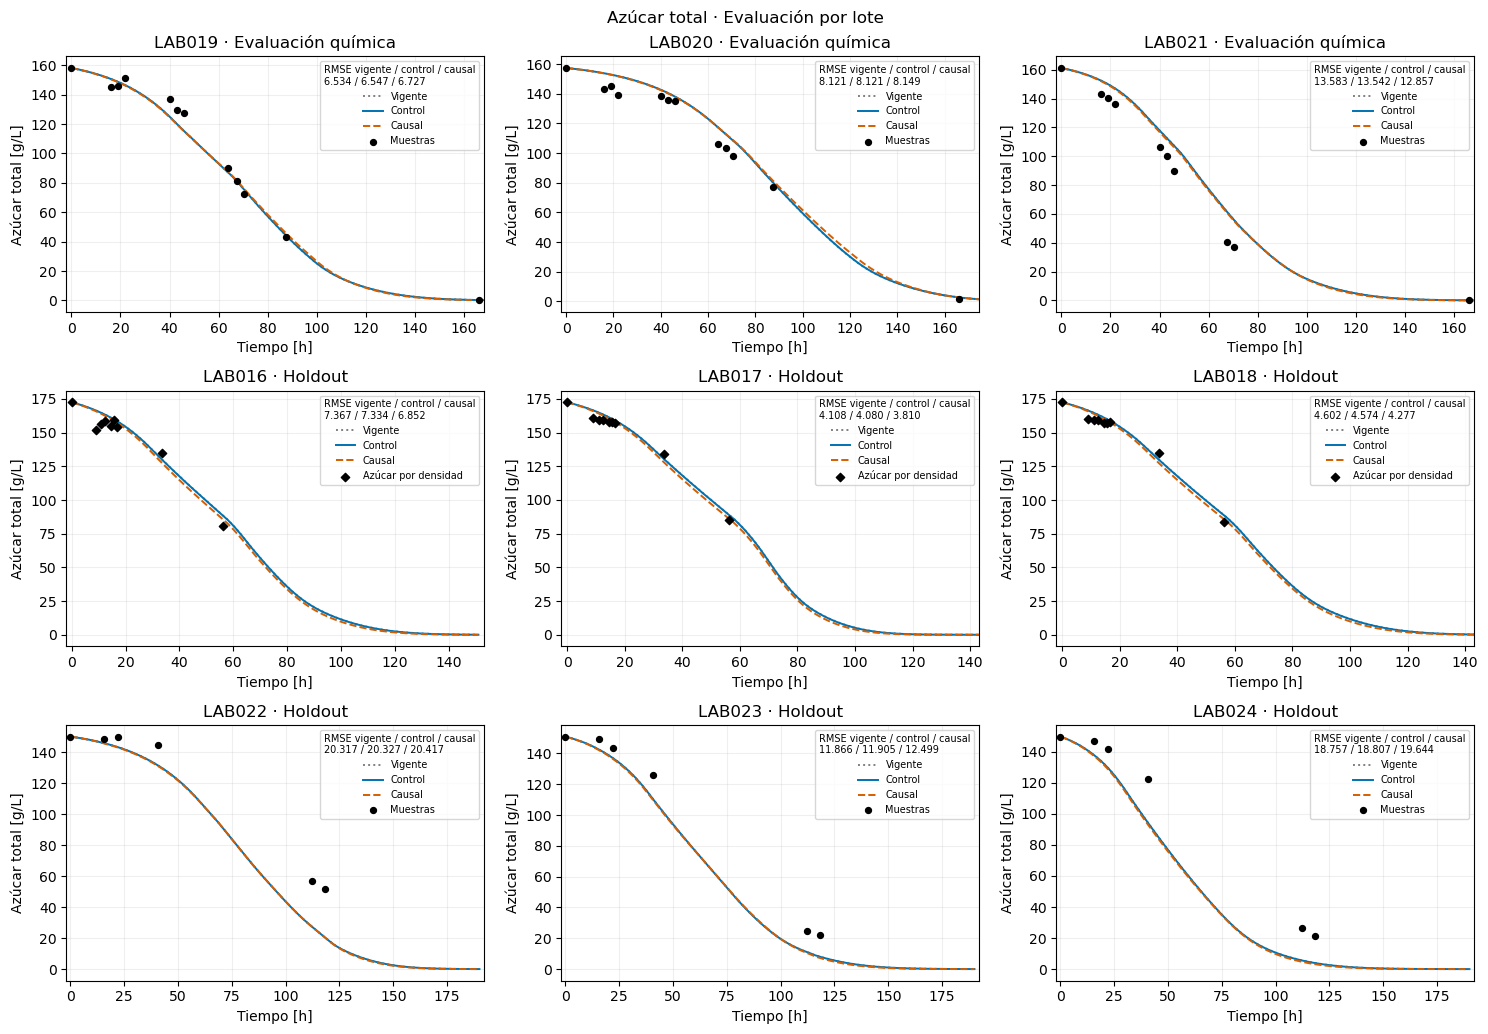

In [19]:
plot_comparison('GF', list(calibration), 'Calibración química')
plot_comparison('GF', [*historical, *recent], 'Evaluación por lote')

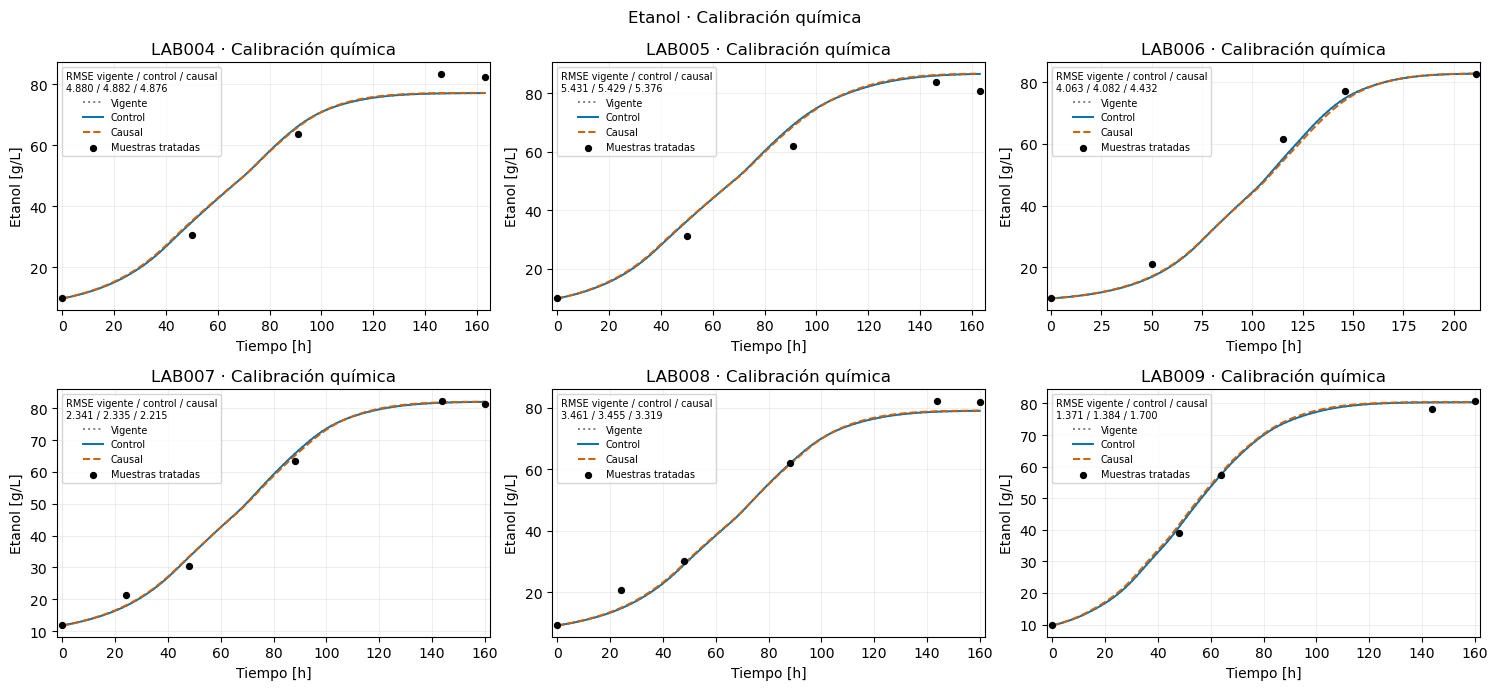

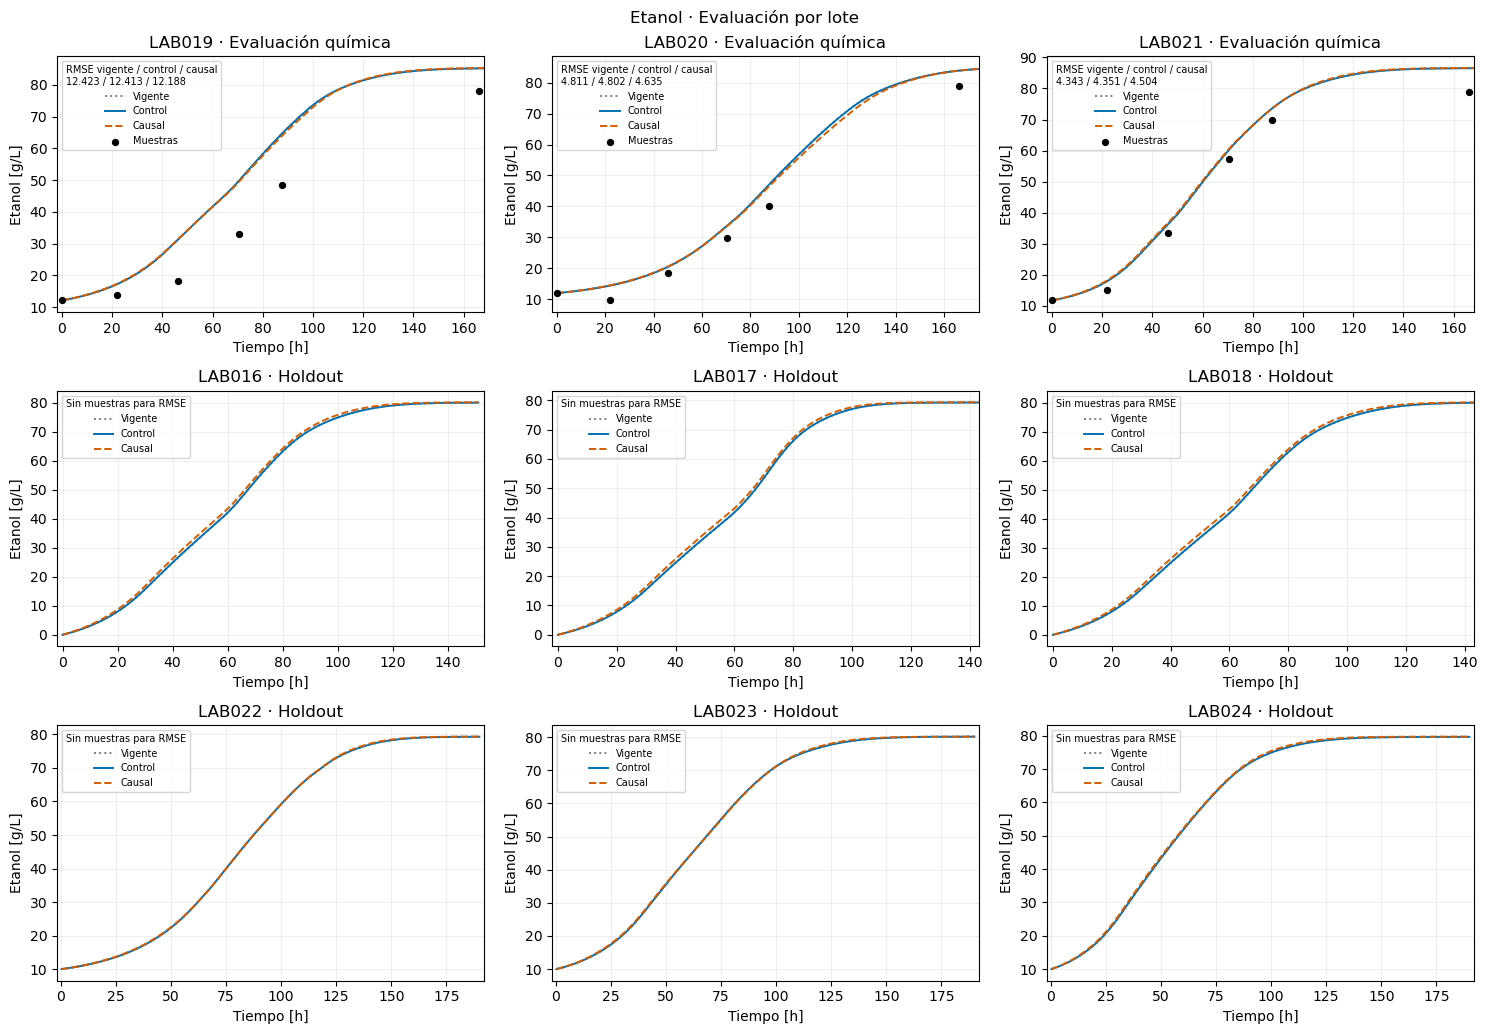

In [20]:
plot_comparison('E', list(calibration), 'Calibración química')
plot_comparison('E', [*historical, *recent], 'Evaluación por lote')